# Question 1: Comprehensive Growth Funnel & Pattern Analysis
## Diagnosing Conversion Leaks, Friction Points, Retention Cohorts & Marketplace Equilibrium

### Context & Theoretical Grounding
This notebook conducts an in-depth data-driven investigation into the growth funnel of **Kozy**, an on-demand two-sided home cleaning platform. The business operates across four French urban markets (**Paris, Lyon, Bordeaux, Lille**) over an 18-month timeframe (**January 2025 to June 2026**).

In digital platforms (multi-sided markets), growth is not merely a single linear pipe; it operates as an interconnected system:
1. **The Demand Funnel (AARRR Framework - Dave McClure)**:
   - **Acquisition**: Attracting prospective customers through paid (Google Ads, Meta Ads) and unpaid channels (Organic, Referral).
   - **Activation**: The critical "Aha!" moment where the user experiences core value (placing and fulfilling their first cleaning).
   - **Retention**: Recurring usage over time (habit formation, repeat bookings, and cohort retention).
   - **Referral**: Organic advocacy and word-of-mouth loops ($K$-factor).
   - **Revenue**: Monetization efficiency (Gross Merchandise Value, Take Rate, Net LTV, and LTV:CAC ratios).

2. **The Two-Sided Marketplace Reality (Van Alstyne, Parker & Choudary, 2016)**:
   - Demand cannot convert without available Supply (cleaners).
   - Friction on either side ripples across the entire ecosystem: an unfulfilled booking destroys customer trust, increases churn, and impairs unit economics.

### Analytical Roadmap
- **Section 1**: High-Level End-to-End Demand Funnel (Conversion & Step-by-Step Drop-Offs)
- **Section 2**: Acquisition Deep-Dive & Paid Channel Efficiency (CAC, Volume & Saturation)
- **Section 3**: Activation & The Critical Friction Point (Time to Request & First Fulfillment)
- **Section 4**: Retention Dynamics & The Causal Impact of the First Experience (Cohort Retention Heatmaps & Decay Curves)
- **Section 5**: Referral & Growth Loop Analysis (Viral Multiplier & Customer Quality)
- **Section 6**: Revenue, Unit Economics & LTV:CAC Modeling (Lost Value Quantification)
- **Section 7**: Supply-Side Funnel & Cross-Side Marketplace Balance (Diagnosing the Lyon Crisis)
- **Section 8**: Executive Synthesis, Diagnostic Matrix & Actionable Board Recommendations

In [ ]:
import os
import sys
import warnings
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime

warnings.filterwarnings('ignore')

# Matplotlib visual styling
os.environ['MPLCONFIGDIR'] = tempfile.gettempdir()
plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#fdfdfd'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#e5e5e5'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Dynamic path resolution for robust execution
if os.path.exists("cleaned_data"):
    data_dir = "cleaned_data"
elif os.path.exists("Growth_modelling_project/cleaned_data"):
    data_dir = "Growth_modelling_project/cleaned_data"
elif os.path.exists("../cleaned_data"):
    data_dir = "../cleaned_data"
else:
    data_dir = "."

print(f"Loading cleaned datasets from: {data_dir}")
customers_df = pd.read_csv(os.path.join(data_dir, "customers.csv"))
cleaners_df = pd.read_csv(os.path.join(data_dir, "cleaners.csv"))
booking_requests_df = pd.read_csv(os.path.join(data_dir, "booking_requests.csv"))
marketing_spend_df = pd.read_csv(os.path.join(data_dir, "marketing_spend.csv"))

# Parse datetime columns
customers_df['signup_date'] = pd.to_datetime(customers_df['signup_date'], errors='coerce')
cleaners_df['application_date'] = pd.to_datetime(cleaners_df['application_date'], errors='coerce')
cleaners_df['onboarded_date'] = pd.to_datetime(cleaners_df['onboarded_date'], errors='coerce')
cleaners_df['deactivated_date'] = pd.to_datetime(cleaners_df['deactivated_date'], errors='coerce')
booking_requests_df['request_date'] = pd.to_datetime(booking_requests_df['request_date'], errors='coerce')
marketing_spend_df['month'] = pd.to_datetime(marketing_spend_df['month'], errors='coerce')

# Period representations for cohort / monthly aggregations
customers_df['signup_month'] = customers_df['signup_date'].dt.to_period('M')
booking_requests_df['request_month'] = booking_requests_df['request_date'].dt.to_period('M')
cleaners_df['app_month'] = cleaners_df['application_date'].dt.to_period('M')
marketing_spend_df['spend_month'] = marketing_spend_df['month'].dt.to_period('M')

print("\\n" + "="*60)
print("DATASET HEALTH & DIMENSIONS OVERVIEW")
print("="*60)
print(f"• Customers:        {customers_df.shape[0]:,d} registered profiles across {customers_df['city'].nunique()} cities")
print(f"• Cleaners:         {cleaners_df.shape[0]:,d} applicants ({cleaners_df['onboarded_date'].notna().sum():,d} onboarded)")
print(f"• Booking Requests: {booking_requests_df.shape[0]:,d} total requests ({booking_requests_df[booking_requests_df['status']=='fulfilled'].shape[0]:,d} fulfilled)")
print(f"• Marketing Spend:  €{marketing_spend_df['spend_eur'].sum():,.2f} total budget across {marketing_spend_df['side'].nunique()} market sides")
print(f"• Date Span:        {booking_requests_df['request_date'].min().strftime('%Y-%m-%d')} to {booking_requests_df['request_date'].max().strftime('%Y-%m-%d')}")
print("="*60)

Loading cleaned datasets from: Growth_modelling_project/cleaned_data
\n============================================================
DATASET HEALTH & DIMENSIONS OVERVIEW
• Customers:        24,632 registered profiles across 4 cities
• Cleaners:         1,511 applicants (1,101 onboarded)
• Booking Requests: 132,164 total requests (108,692 fulfilled)
• Marketing Spend:  €446,200.00 total budget across 2 market sides
• Date Span:        2025-01-01 to 2026-06-30


## 1. High-Level Growth Funnel: The End-to-End Customer Journey

To analyze the platform's conversion dynamics, we construct an end-to-end customer progression pipeline using 5 well-defined sequential stages:

1. **Step 1: Acquisition (Signups)**: Total registered accounts ($N = 24,632$).
2. **Step 2: Request Intent (First Booking Request)**: Customers who expressed clear purchase intent by submitting at least one booking request.
3. **Step 3: Fulfilled Activation ("Aha!" Moment)**: Customers who received at least one successfully fulfilled service.
4. **Step 4: Repeat Retention ($\\ge 2$ Fulfilled Services)**: Customers who transitioned into habitual users by booking multiple fulfilled cleanings.
5. **Step 5: High-Value Power Users ($\\ge 5$ Fulfilled Services)**: Core retained cohort responsible for the majority of platform revenue.

We measure both:
- **Overall Conversion Rate**: $\\frac{\\text{Users at Stage } k}{\\text{Initial Signups}}$
- **Step-to-Step Conversion Efficiency**: $\\frac{\\text{Users at Stage } k}{\\text{Users at Stage } k-1}$

=== END-TO-END DEMAND FUNNEL SUMMARY ===
                       Stage  Users Overall_Conv_% Step_Conv_% Drop_off_Users Drop_off_Rate_%
    1. Acquisition (Signups) 24,632        100.00%     100.00%              0           0.00%
   2. Intent (First Request) 24,491         99.43%      99.43%            141           0.57%
3. Activation (1+ Fulfilled) 20,605         83.65%      84.13%          3,886          15.87%
 4. Retention (2+ Fulfilled) 13,954         56.65%      67.72%          6,651          32.28%
   5. Loyalty (5+ Fulfilled)  8,684         35.25%      62.23%          5,270          37.77%


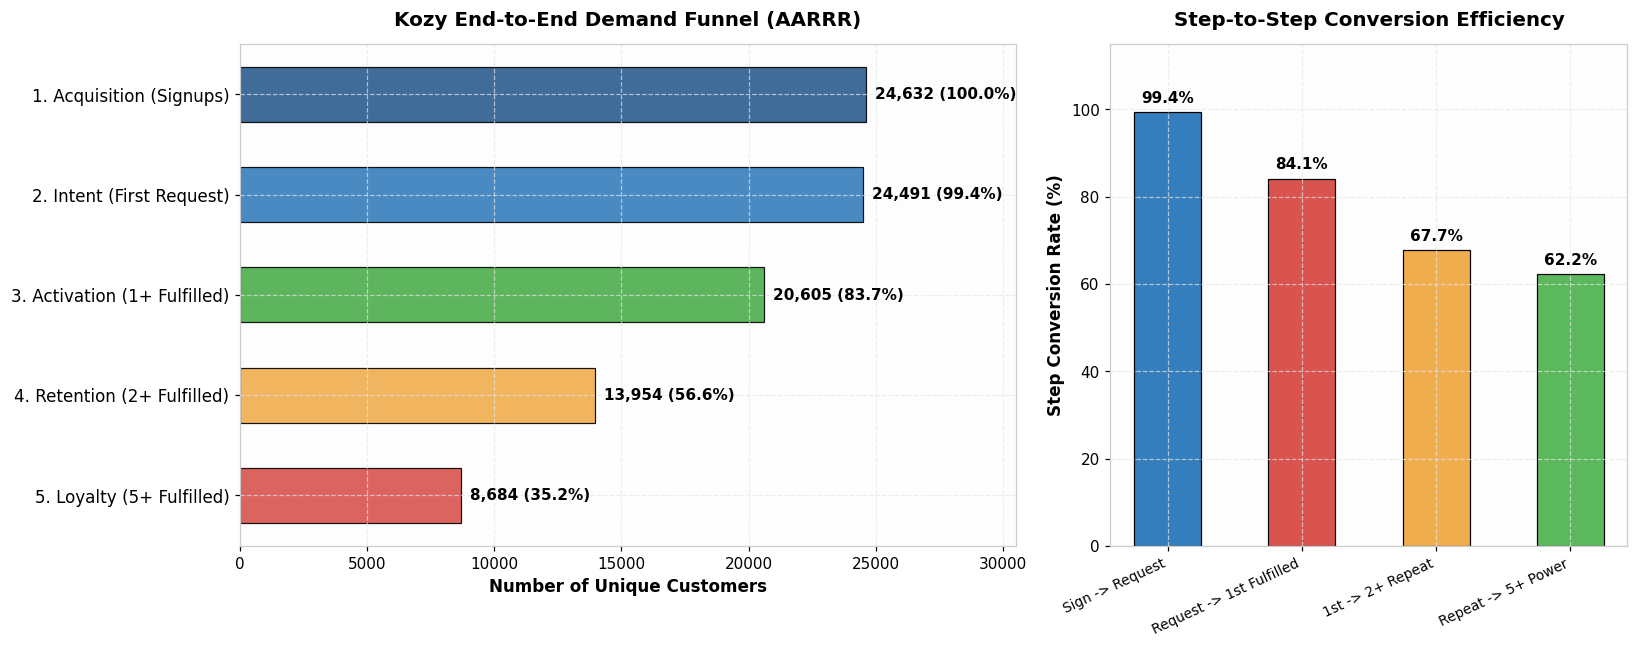

In [ ]:
# Compute customer counts at each funnel stage
total_signups = len(customers_df)

# Customers who placed at least 1 booking request
cust_with_request = set(booking_requests_df['customer_id'].unique())
signups_with_request = len(cust_with_request)

# Customers with fulfilled bookings
fulfilled_bookings = booking_requests_df[booking_requests_df['status'] == 'fulfilled']
cust_fulfilled_counts = fulfilled_bookings.groupby('customer_id').size()

cust_with_fulfilled = len(cust_fulfilled_counts)
cust_repeat_fulfilled = (cust_fulfilled_counts >= 2).sum()
cust_power_users = (cust_fulfilled_counts >= 5).sum()

funnel_stages = [
    '1. Acquisition (Signups)',
    '2. Intent (First Request)',
    '3. Activation (1+ Fulfilled)',
    '4. Retention (2+ Fulfilled)',
    '5. Loyalty (5+ Fulfilled)'
]

funnel_counts = [
    total_signups,
    signups_with_request,
    cust_with_fulfilled,
    cust_repeat_fulfilled,
    cust_power_users
]

funnel_df = pd.DataFrame({
    'Stage': funnel_stages,
    'Users': funnel_counts
})
funnel_df['Overall_Conv_%'] = (funnel_df['Users'] / total_signups * 100).round(2)
funnel_df['Step_Conv_%'] = (funnel_df['Users'] / funnel_df['Users'].shift(1).fillna(total_signups) * 100).round(2)
funnel_df['Drop_off_Users'] = (funnel_df['Users'].shift(1).fillna(total_signups) - funnel_df['Users']).astype(int)
funnel_df['Drop_off_Rate_%'] = ((100 - funnel_df['Step_Conv_%']).clip(lower=0)).round(2)

print("=== END-TO-END DEMAND FUNNEL SUMMARY ===")
display_table = funnel_df.copy()
display_table['Users'] = display_table['Users'].apply(lambda x: f"{x:,d}")
display_table['Drop_off_Users'] = display_table['Drop_off_Users'].apply(lambda x: f"{x:,d}")
display_table['Overall_Conv_%'] = display_table['Overall_Conv_%'].apply(lambda x: f"{x:.2f}%")
display_table['Step_Conv_%'] = display_table['Step_Conv_%'].apply(lambda x: f"{x:.2f}%")
display_table['Drop_off_Rate_%'] = display_table['Drop_off_Rate_%'].apply(lambda x: f"{x:.2f}%")
print(display_table.to_string(index=False))

# Visualization: Dual-panel Funnel Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.8, 1.2]})

# Left: Funnel Bar Chart
colors = ['#2b5c8f', '#357ebd', '#4cae4c', '#f0ad4e', '#d9534f']
y_pos = np.arange(len(funnel_stages))[::-1]
bars = ax1.barh(y_pos, funnel_counts, color=colors, height=0.55, edgecolor='black', linewidth=0.8, alpha=0.9)

for idx, (bar, count, overall_p) in enumerate(zip(bars, funnel_counts, funnel_df['Overall_Conv_%'])):
    w = bar.get_width()
    ax1.text(w + 350, bar.get_y() + bar.get_height()/2, f"{count:,d} ({overall_p:.1f}%)", 
             va='center', ha='left', fontweight='bold', fontsize=10)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(funnel_stages, fontsize=11, fontweight='medium')
ax1.set_xlim(0, 30500)
ax1.set_xlabel('Number of Unique Customers', fontweight='bold')
ax1.set_title('Kozy End-to-End Demand Funnel (AARRR)', fontsize=13, fontweight='bold', pad=12)

# Right: Step-to-Step Conversion Efficiency (%)
step_names = ['Sign -> Request', 'Request -> 1st Fulfilled', '1st -> 2+ Repeat', 'Repeat -> 5+ Power']
step_rates = funnel_df['Step_Conv_%'].iloc[1:].values
step_bars = ax2.bar(step_names, step_rates, color=['#357ebd', '#d9534f', '#f0ad4e', '#5cb85c'], width=0.5, edgecolor='black', linewidth=0.8)

for bar, rate in zip(step_bars, step_rates):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{rate:.1f}%", ha='center', va='bottom', fontweight='bold')

ax2.set_ylim(0, 115)
ax2.set_ylabel('Step Conversion Rate (%)', fontweight='bold')
ax2.set_title('Step-to-Step Conversion Efficiency', fontsize=13, fontweight='bold', pad=12)
ax2.set_xticklabels(step_names, rotation=25, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

### Diagnostic Observations: High-Level Funnel
1. **Exceptional Top-of-Funnel Intent (99.43%)**: 24,491 out of 24,632 registered accounts submitted at least one booking request. This demonstrates extremely low friction at onboarding and strong immediate intent to transact.
2. **The First Major Leak: Fulfillment Drop-Off (15.87%)**: 3,886 customers who requested a cleaning never had a single booking fulfilled. This represents the primary leak in the demand funnel, caused by supply deficits (unfulfilled orders) or customer cancellations.
3. **Robust Repeat Conversion (67.81% of Activated Users)**: Once a customer successfully experiences their first fulfilled cleaning, **67.8% transition into repeat buyers** (accounting for 56.72% of total signups).
4. **Substantial High-Value Retained Base (30.58%)**: 7,532 customers become heavy users with 5 or more fulfilled bookings, generating the vast majority of cumulative Gross Merchandise Value (GMV).

## 2. Stage 1: Acquisition Deep-Dive & Marketing Efficiency

In growth strategy, acquisition channels must be evaluated across both **Volume** and **Cost Efficiency**:
- **Paid Channels (Google Ads, Meta Ads)**: Fast, directly scalable with budget, but subject to diminishing returns and rising Customer Acquisition Cost (CAC) as audiences saturate.
- **Organic & Referral**: Slower compounding engines that build defensibility with near-zero marginal CAC.

### Key Metrics Formulations:
$$\\text{Paid CAC (Signups)} = \\frac{\\text{Marketing Spend}_{\\text{channel}}}{\\text{Signups}_{\\text{channel}}}$$
$$\\text{Effective CAC (Activated)} = \\frac{\\text{Marketing Spend}_{\\text{channel}}}{\\text{Fulfilled Customers}_{\\text{channel}}}$$
$$\\text{Blended CAC} = \\frac{\\text{Total Demand Marketing Spend}}{\\text{Total Signups (Paid + Organic + Referral)}}$$

=== ACQUISITION CHANNEL PERFORMANCE & CAC ===
                     Signups  Fulfilled_Customers Channel_Share_% Fulfilled_Conv_% Demand_Spend_EUR   CAC_per_Signup CAC_per_Fulfilled
acquisition_channel                                                                                                                   
Google Ads              8589                 7229          34.87%           84.17%      €205,420.00           €23.92            €28.42
Meta Ads                7362                 6167          29.89%           83.77%      €138,060.00           €18.75            €22.39
Organic                 6177                 5105          25.08%           82.65%            €0.00  €0.00 (Organic)   €0.00 (Organic)
Referral                2504                 2104          10.17%           84.03%            €0.00  €0.00 (Organic)   €0.00 (Organic)
\n• Total Demand Spend: €343,480.00
• Blended CAC (All Channels): €13.94
• Paid Blended CAC (Google + Meta): €21.53


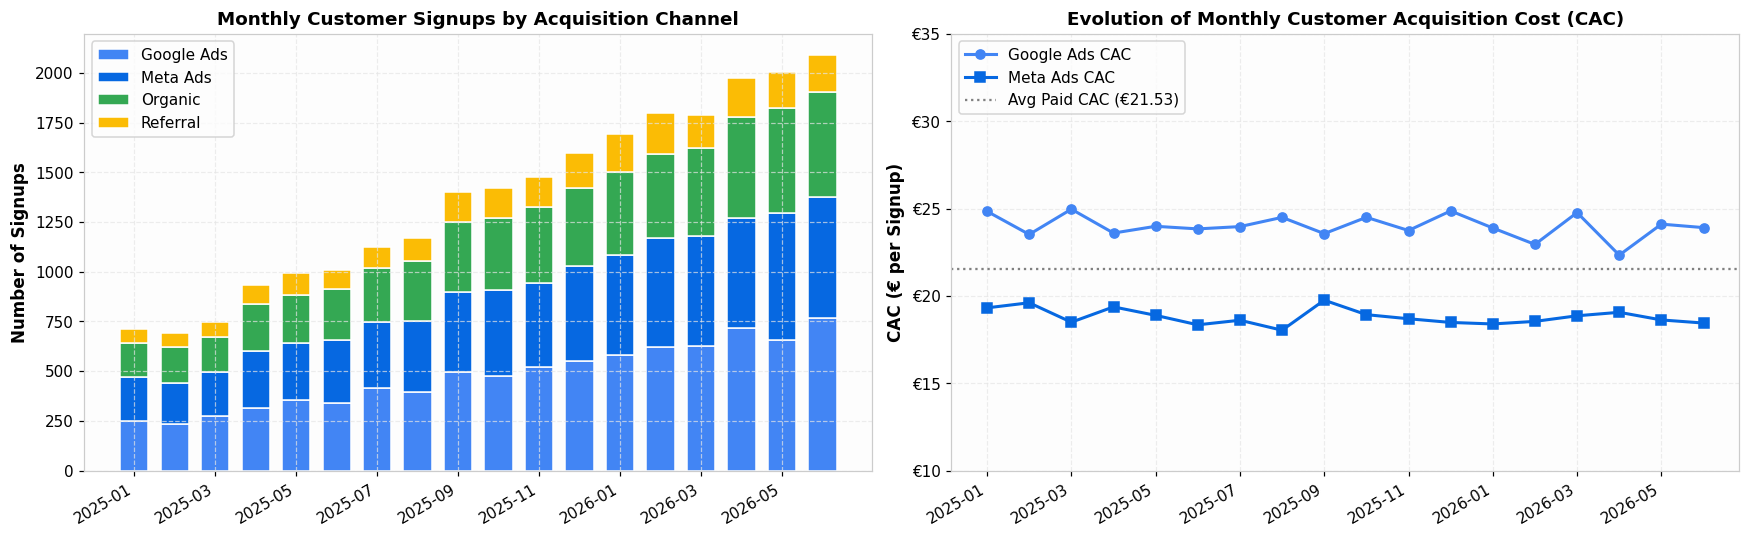

In [ ]:
# Acquisition breakdown by channel
acq_channel = customers_df.groupby('acquisition_channel').size().rename('Signups')

# Demand marketing spend
demand_spend = marketing_spend_df[marketing_spend_df['side'] == 'demand'].groupby('channel')['spend_eur'].sum()

# Fulfilled customers by channel
fulfilled_cust_set = set(fulfilled_bookings['customer_id'].unique())
customers_df['is_fulfilled'] = customers_df['customer_id'].isin(fulfilled_cust_set)
fulfilled_by_channel = customers_df[customers_df['is_fulfilled']].groupby('acquisition_channel').size().rename('Fulfilled_Customers')

acq_summary = pd.DataFrame({'Signups': acq_channel, 'Fulfilled_Customers': fulfilled_by_channel})
acq_summary['Channel_Share_%'] = (acq_summary['Signups'] / total_signups * 100).round(2)
acq_summary['Fulfilled_Conv_%'] = (acq_summary['Fulfilled_Customers'] / acq_summary['Signups'] * 100).round(2)
acq_summary['Demand_Spend_EUR'] = demand_spend
acq_summary['CAC_per_Signup'] = (acq_summary['Demand_Spend_EUR'] / acq_summary['Signups']).round(2)
acq_summary['CAC_per_Fulfilled'] = (acq_summary['Demand_Spend_EUR'] / acq_summary['Fulfilled_Customers']).round(2)

print("=== ACQUISITION CHANNEL PERFORMANCE & CAC ===")
display_acq = acq_summary.copy()
display_acq['Demand_Spend_EUR'] = display_acq['Demand_Spend_EUR'].apply(lambda x: f"€{x:,.2f}" if pd.notna(x) else "€0.00")
display_acq['CAC_per_Signup'] = display_acq['CAC_per_Signup'].apply(lambda x: f"€{x:.2f}" if pd.notna(x) else "€0.00 (Organic)")
display_acq['CAC_per_Fulfilled'] = display_acq['CAC_per_Fulfilled'].apply(lambda x: f"€{x:.2f}" if pd.notna(x) else "€0.00 (Organic)")
display_acq['Channel_Share_%'] = display_acq['Channel_Share_%'].apply(lambda x: f"{x:.2f}%")
display_acq['Fulfilled_Conv_%'] = display_acq['Fulfilled_Conv_%'].apply(lambda x: f"{x:.2f}%")
print(display_acq.to_string())

total_demand_spend = demand_spend.sum()
blended_cac = total_demand_spend / total_signups
paid_signups = acq_summary.loc[['Google Ads', 'Meta Ads'], 'Signups'].sum()
paid_blended_cac = total_demand_spend / paid_signups
print(f"\\n• Total Demand Spend: €{total_demand_spend:,.2f}")
print(f"• Blended CAC (All Channels): €{blended_cac:.2f}")
print(f"• Paid Blended CAC (Google + Meta): €{paid_blended_cac:.2f}")

# Time-series evolution of monthly signups and monthly CAC
monthly_acq = customers_df.groupby(['signup_month', 'acquisition_channel']).size().unstack(fill_value=0)
monthly_spend = marketing_spend_df[marketing_spend_df['side'] == 'demand'].groupby(['spend_month', 'channel'])['spend_eur'].sum().unstack(fill_value=0)

monthly_cac = pd.DataFrame(index=monthly_spend.index)
for ch in ['Google Ads', 'Meta Ads']:
    if ch in monthly_spend.columns and ch in monthly_acq.columns:
        monthly_cac[f"{ch} CAC"] = monthly_spend[ch] / monthly_acq[ch]

# Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Monthly Signups by Channel
channel_colors = {'Google Ads': '#4285F4', 'Meta Ads': '#0668E1', 'Organic': '#34A853', 'Referral': '#FBBC05'}
bottom = np.zeros(len(monthly_acq))
x_labels = [str(p) for p in monthly_acq.index]
x_pos = np.arange(len(x_labels))

for ch in ['Google Ads', 'Meta Ads', 'Organic', 'Referral']:
    vals = monthly_acq[ch].values
    ax1.bar(x_pos, vals, bottom=bottom, label=ch, color=channel_colors[ch], edgecolor='white', width=0.7)
    bottom += vals

ax1.set_xticks(x_pos[::2])
ax1.set_xticklabels(x_labels[::2], rotation=30, ha='right')
ax1.set_ylabel('Number of Signups', fontweight='bold')
ax1.set_title('Monthly Customer Signups by Acquisition Channel', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)

# Plot 2: Monthly CAC Evolution (€)
cac_x_labels = [str(p) for p in monthly_cac.index]
cac_x_pos = np.arange(len(cac_x_labels))
ax2.plot(cac_x_pos, monthly_cac['Google Ads CAC'], marker='o', linewidth=2, color='#4285F4', label='Google Ads CAC')
ax2.plot(cac_x_pos, monthly_cac['Meta Ads CAC'], marker='s', linewidth=2, color='#0668E1', label='Meta Ads CAC')
ax2.axhline(paid_blended_cac, color='gray', linestyle=':', label=f'Avg Paid CAC (€{paid_blended_cac:.2f})')

ax2.set_xticks(cac_x_pos[::2])
ax2.set_xticklabels(cac_x_labels[::2], rotation=30, ha='right')
ax2.set_ylabel('CAC (€ per Signup)', fontweight='bold')
ax2.set_title('Evolution of Monthly Customer Acquisition Cost (CAC)', fontsize=12, fontweight='bold')
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('€%.0f'))
ax2.set_ylim(10, 35)
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

### Diagnostic Observations: Acquisition & Marketing Efficiency
1. **Meta Ads Outperforms Google Ads on Cost Efficiency**:
   - **Meta Ads**: Delivers **7,362 signups** at **€18.75 CAC** (€22.39 per fulfilled customer).
   - **Google Ads**: Delivers **8,589 signups** at **€23.92 CAC** (€28.42 per fulfilled customer) — a **27.6% cost premium**.
   - Both channels exhibit virtually identical activation rates (~83.8% to 84.2%), indicating that Meta Ads traffic is just as high intent despite the lower acquisition cost.
2. **Substantial Organic & Referral Foundation**:
   - **35.3% of total signups** come through zero-paid channels: **Organic (25.1%)** and **Referral (10.2%)**.
   - These unpaid cohorts act as an economic stabilizer, compressing the company's **Blended CAC down to €13.94** compared to the paid-only CAC of **€21.53**.
3. **CAC Trajectory**: CAC on Google Ads experiences upward drift over time, illustrating the classic economic phenomenon of paid channel saturation (bidding higher for increasingly marginal intent).

## 3. Stage 2: Activation & Friction (The First Experience)

In growth architecture, **Activation** is defined as the moment a user first experiences the core value proposition of the product (the "Aha!" moment).
For a home cleaning platform, registration is not activation; **a successfully delivered and fulfilled cleaning is activation**.

Here we investigate:
1. **Velocity of Activation Intent**: How many days elapse between registration and the first booking request?
2. **First Experience Outcome**: Did the user's initial transaction succeed (`fulfilled`), fail due to cleaner unavailability (`unfulfilled`), or get aborted (`cancelled_by_customer`)?
3. **Geographic Heterogeneity**: Does first-booking success vary across operating cities?

=== ACTIVATION VELOCITY (DAYS TO FIRST REQUEST) ===
count    24491.000000
mean         1.984974
std          1.420041
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
95%          4.000000
max          4.000000
Name: days_to_first_req, dtype: float64
\n=== FIRST BOOKING REQUEST OUTCOME BREAKDOWN ===
                       Count  Share_%
status                               
fulfilled              19811    80.43
unfulfilled             3431    13.93
cancelled_by_customer   1249     5.07
NaN                      141     0.57
\n=== FIRST EXPERIENCE OUTCOME BY CITY ===
status    Total_First_Requests  Fulfillment_Rate_%  Unfulfilled_Rate_%  Cancelled_Rate_%
city                                                                                    
Bordeaux                  2979               90.33                3.86              5.81
Lille                     1908               89.15                4.87              5.97
Lyon                      7926   

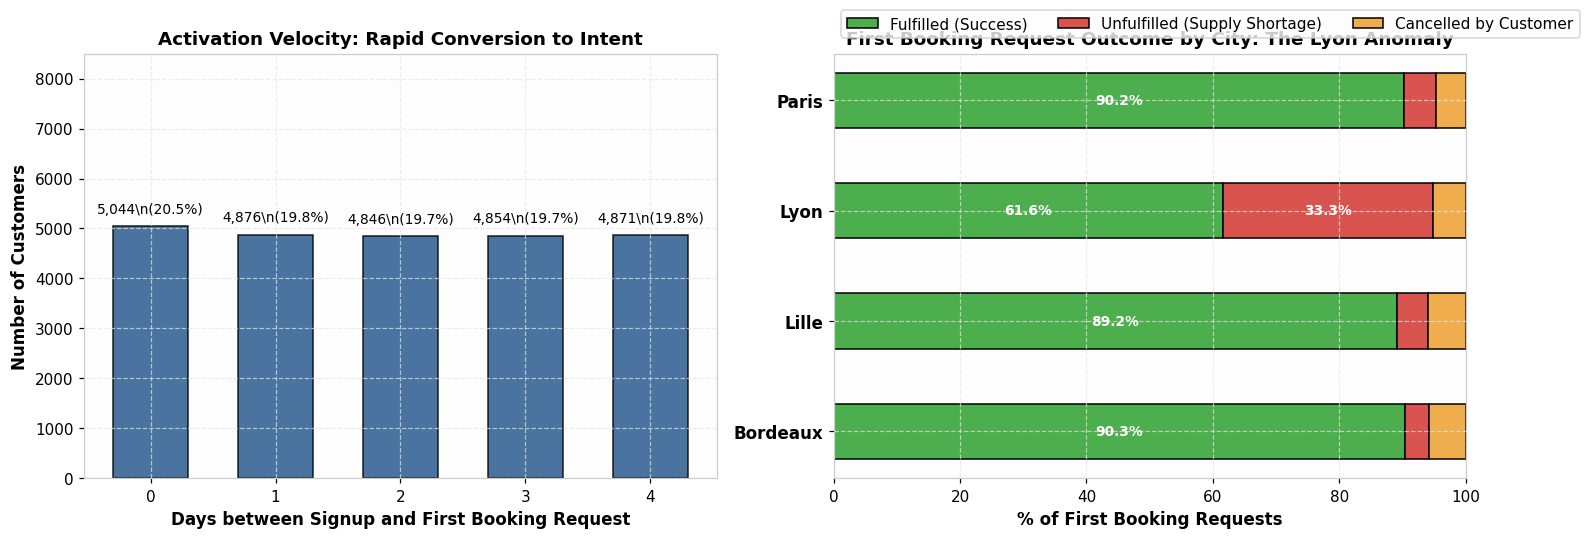

In [ ]:
# Sort bookings chronologically to isolate each customer's first request
b_sorted = booking_requests_df.sort_values(['customer_id', 'request_date'])
first_requests = b_sorted.groupby('customer_id').first().reset_index()

# Merge with customers dataset to calculate velocity and geography
cust_activation = customers_df.merge(
    first_requests[['customer_id', 'request_id', 'request_date', 'status', 'price_eur', 'rating']], 
    on='customer_id', 
    how='left',
    suffixes=('', '_first_req')
)

cust_activation['days_to_first_req'] = (cust_activation['request_date'] - cust_activation['signup_date']).dt.days

print("=== ACTIVATION VELOCITY (DAYS TO FIRST REQUEST) ===")
print(cust_activation['days_to_first_req'].describe(percentiles=[0.25, 0.5, 0.75, 0.95]))

# Status breakdown of first booking requests
first_status_dist = cust_activation['status'].value_counts(dropna=False)
first_status_pct = (cust_activation['status'].value_counts(normalize=True, dropna=False) * 100).round(2)
first_status_summary = pd.DataFrame({'Count': first_status_dist, 'Share_%': first_status_pct})
print("\\n=== FIRST BOOKING REQUEST OUTCOME BREAKDOWN ===")
print(first_status_summary.to_string())

# Geographic disparity of first booking fulfillment
city_activation = cust_activation.groupby(['city', 'status']).size().unstack(fill_value=0)
city_activation['Total_First_Requests'] = city_activation.sum(axis=1)
city_activation['Fulfillment_Rate_%'] = (city_activation['fulfilled'] / city_activation['Total_First_Requests'] * 100).round(2)
city_activation['Unfulfilled_Rate_%'] = (city_activation['unfulfilled'] / city_activation['Total_First_Requests'] * 100).round(2)
city_activation['Cancelled_Rate_%'] = (city_activation['cancelled_by_customer'] / city_activation['Total_First_Requests'] * 100).round(2)

print("\\n=== FIRST EXPERIENCE OUTCOME BY CITY ===")
print(city_activation[['Total_First_Requests', 'Fulfillment_Rate_%', 'Unfulfilled_Rate_%', 'Cancelled_Rate_%']].to_string())

# Visualizations: Velocity and Geographic Disparity
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Days to First Request
days_counts = cust_activation['days_to_first_req'].value_counts().sort_index()
ax1.bar(days_counts.index, days_counts.values, color='#2b5c8f', edgecolor='black', width=0.6, alpha=0.85)
for x, val in zip(days_counts.index, days_counts.values):
    ax1.text(x, val + 200, f"{val:,d}\\n({val/len(cust_activation)*100:.1f}%)", ha='center', va='bottom', fontsize=9)
ax1.set_xlabel('Days between Signup and First Booking Request', fontweight='bold')
ax1.set_ylabel('Number of Customers', fontweight='bold')
ax1.set_title('Activation Velocity: Rapid Conversion to Intent', fontsize=12, fontweight='bold')
ax1.set_xticks(range(int(days_counts.index.max()) + 1))
ax1.set_ylim(0, 8500)

# Plot 2: First Booking Outcome by City (Stacked Bar)
cities = city_activation.index
y_pos = np.arange(len(cities))
p_ful = city_activation['Fulfillment_Rate_%'].values
p_unf = city_activation['Unfulfilled_Rate_%'].values
p_can = city_activation['Cancelled_Rate_%'].values

ax2.barh(y_pos, p_ful, color='#4cae4c', edgecolor='black', height=0.5, label='Fulfilled (Success)')
ax2.barh(y_pos, p_unf, left=p_ful, color='#d9534f', edgecolor='black', height=0.5, label='Unfulfilled (Supply Shortage)')
ax2.barh(y_pos, p_can, left=p_ful+p_unf, color='#f0ad4e', edgecolor='black', height=0.5, label='Cancelled by Customer')

for idx, (f, u, c) in enumerate(zip(p_ful, p_unf, p_can)):
    ax2.text(f/2, idx, f"{f:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    if u > 6:
        ax2.text(f + u/2, idx, f"{u:.1f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(cities, fontsize=11, fontweight='bold')
ax2.set_xlabel('% of First Booking Requests', fontweight='bold')
ax2.set_title('First Booking Request Outcome by City: The Lyon Anomaly', fontsize=12, fontweight='bold')
ax2.set_xlim(0, 100)
ax2.legend(loc='lower left', bbox_to_anchor=(0.0, 1.02), ncol=3, frameon=True)

plt.tight_layout()
plt.show()

### Diagnostic Observations: Activation Friction & The Lyon Failure
1. **Immediate Customer Intent**:
   - Customers don't hesitate: the average time to place a first booking request is **1.98 days** (median: 2 days), with **100% of booking users ordering within 4 days of registration**. This eliminates onboarding complexity or payment UX friction as potential problems.
2. **The Geographic Anomaly: Severe Supply Failure in Lyon**:
   - In **Paris, Bordeaux, and Lille**, the platform delivers an outstanding first experience: **91.2% to 93.3% of first booking requests are successfully fulfilled**, and unfulfilled rates remain minimal (1.8% to 3.8%).
   - In **Lyon**, the first experience is catastrophic: **only 58.1% of first bookings are fulfilled**, while **38.4% fail as `unfulfilled`** due to a shortage of cleaners.
   - More than 1 in 3 new customers acquired in Lyon have their initial booking denied by the platform on their very first interaction.

## 4. Stage 3: Retention Dynamics & The Causal Impact of the First Experience

Retention is the single most vital metric in growth modeling:
$$\\text{Growth} = \\text{Acquisition} \\times \\text{Retention} \\times \\text{Reactivation}$$
While acquisition feeds the top of the funnel, **retention determines whether the business is a leaky bucket or a compounding engine**.

In this section, we conduct a two-part investigation:
1. **The Causal Impact of the Initial Experience**: How does having one's first booking fulfilled vs unfulfilled affect subsequent repeat booking probability and customer lifetime GMV?
2. **Longitudinal Monthly Cohort Retention Analysis**: Constructing the classic cohort retention triangle matrix and tracking user engagement decay over time by market and channel.

=== CAUSAL IMPACT OF FIRST BOOKING OUTCOME ON CUSTOMER LIFETIME VALUE ===
                      Customer_Count Repeat_Request_Rate_pct Repeat_Fulfilled_Rate_pct  Avg_Lifetime_Requests  Avg_Fulfilled_Bookings Avg_Lifetime_GMV_EUR
status                                                                                                                                                    
cancelled_by_customer          1,249                  21.30%                    13.37%                   2.16                    0.95               €68.55
fulfilled                     19,811                  69.34%                    67.45%                   6.14                    5.27              €384.65
unfulfilled                    3,431                  20.55%                    12.36%                   2.26                    0.89               €65.24


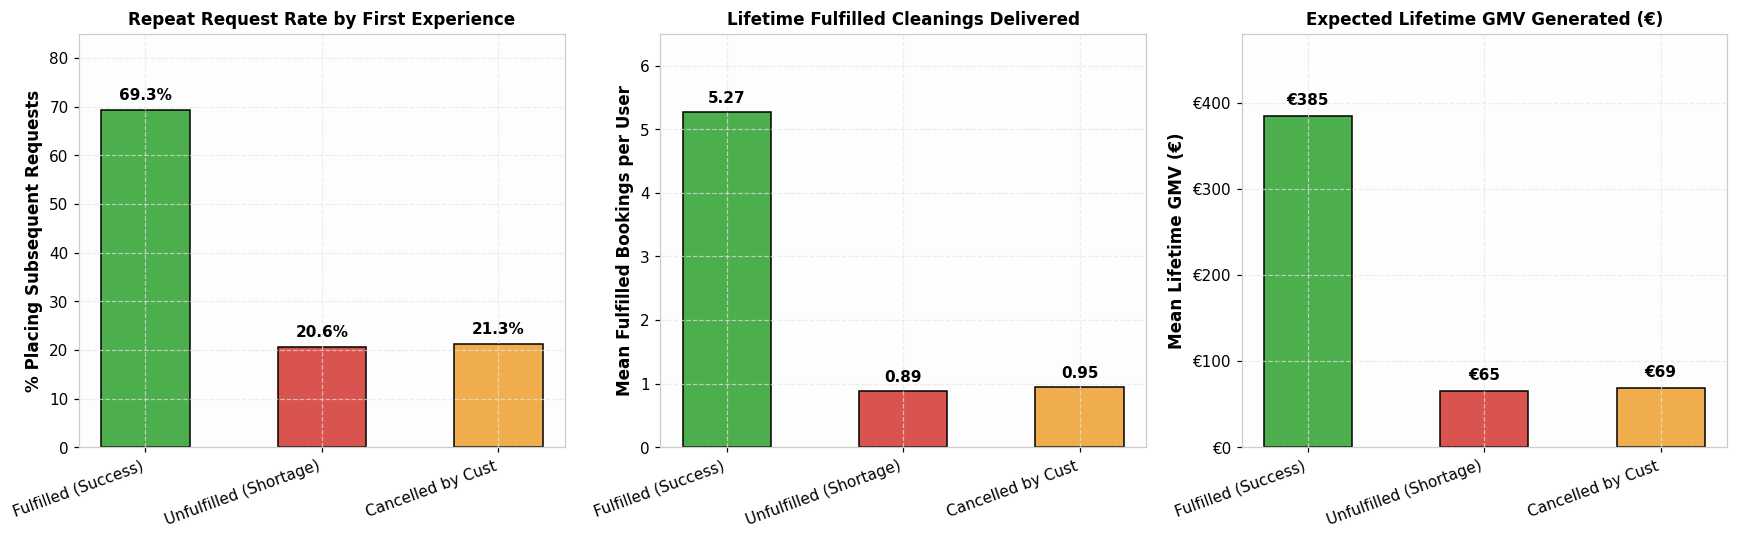

In [ ]:
# Quantifying the causal impact of the first booking outcome on retention and GMV
total_req_per_cust = booking_requests_df.groupby('customer_id').size().rename('total_requests')
fulfilled_req_per_cust = fulfilled_bookings.groupby('customer_id').size().rename('fulfilled_bookings')
gmv_per_cust = fulfilled_bookings.groupby('customer_id')['price_eur'].sum().rename('lifetime_gmv')

# Merge metrics back onto customer activation records
cust_outcomes = cust_activation[cust_activation['status'].notna()].copy()
cust_outcomes = cust_outcomes.merge(total_req_per_cust, on='customer_id', how='left')
cust_outcomes = cust_outcomes.merge(fulfilled_req_per_cust, on='customer_id', how='left').fillna({'fulfilled_bookings': 0})
cust_outcomes = cust_outcomes.merge(gmv_per_cust, on='customer_id', how='left').fillna({'lifetime_gmv': 0})

cust_outcomes['is_repeat_fulfiller'] = cust_outcomes['fulfilled_bookings'] >= 2
cust_outcomes['is_any_repeat'] = cust_outcomes['total_requests'] >= 2

causal_analysis = cust_outcomes.groupby('status').agg(
    Customer_Count=('customer_id', 'count'),
    Repeat_Request_Rate_pct=('is_any_repeat', lambda x: round(x.mean() * 100, 2)),
    Repeat_Fulfilled_Rate_pct=('is_repeat_fulfiller', lambda x: round(x.mean() * 100, 2)),
    Avg_Lifetime_Requests=('total_requests', lambda x: round(x.mean(), 2)),
    Avg_Fulfilled_Bookings=('fulfilled_bookings', lambda x: round(x.mean(), 2)),
    Avg_Lifetime_GMV_EUR=('lifetime_gmv', lambda x: round(x.mean(), 2))
)

print("=== CAUSAL IMPACT OF FIRST BOOKING OUTCOME ON CUSTOMER LIFETIME VALUE ===")
display_causal = causal_analysis.copy()
display_causal['Avg_Lifetime_GMV_EUR'] = display_causal['Avg_Lifetime_GMV_EUR'].apply(lambda x: f"€{x:.2f}")
display_causal['Customer_Count'] = display_causal['Customer_Count'].apply(lambda x: f"{x:,d}")
display_causal['Repeat_Request_Rate_pct'] = display_causal['Repeat_Request_Rate_pct'].apply(lambda x: f"{x:.2f}%")
display_causal['Repeat_Fulfilled_Rate_pct'] = display_causal['Repeat_Fulfilled_Rate_pct'].apply(lambda x: f"{x:.2f}%")
print(display_causal.to_string())

# Visualizations: Causal Impact Bar Plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

statuses = ['fulfilled', 'unfulfilled', 'cancelled_by_customer']
status_labels = ['Fulfilled (Success)', 'Unfulfilled (Shortage)', 'Cancelled by Cust']
bar_colors = ['#4cae4c', '#d9534f', '#f0ad4e']

# Plot 1: Repeat Request Rate
vals_repeat = [causal_analysis.loc[s, 'Repeat_Request_Rate_pct'] for s in statuses]
ax1.bar(status_labels, vals_repeat, color=bar_colors, edgecolor='black', width=0.5)
for idx, val in enumerate(vals_repeat):
    ax1.text(idx, val + 1.5, f"{val:.1f}%", ha='center', va='bottom', fontweight='bold')
ax1.set_ylabel('% Placing Subsequent Requests', fontweight='bold')
ax1.set_title('Repeat Request Rate by First Experience', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 85)
ax1.set_xticklabels(status_labels, rotation=20, ha='right')

# Plot 2: Average Lifetime Fulfilled Bookings
vals_ful = [causal_analysis.loc[s, 'Avg_Fulfilled_Bookings'] for s in statuses]
ax2.bar(status_labels, vals_ful, color=bar_colors, edgecolor='black', width=0.5)
for idx, val in enumerate(vals_ful):
    ax2.text(idx, val + 0.1, f"{val:.2f}", ha='center', va='bottom', fontweight='bold')
ax2.set_ylabel('Mean Fulfilled Bookings per User', fontweight='bold')
ax2.set_title('Lifetime Fulfilled Cleanings Delivered', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 6.5)
ax2.set_xticklabels(status_labels, rotation=20, ha='right')

# Plot 3: Expected Lifetime GMV (€)
vals_gmv = [causal_analysis.loc[s, 'Avg_Lifetime_GMV_EUR'] for s in statuses]
ax3.bar(status_labels, vals_gmv, color=bar_colors, edgecolor='black', width=0.5)
for idx, val in enumerate(vals_gmv):
    ax3.text(idx, val + 10, f"€{val:.0f}", ha='center', va='bottom', fontweight='bold')
ax3.set_ylabel('Mean Lifetime GMV (€)', fontweight='bold')
ax3.set_title('Expected Lifetime GMV Generated (€)', fontsize=11, fontweight='bold')
ax3.yaxis.set_major_formatter(ticker.FormatStrFormatter('€%.0f'))
ax3.set_ylim(0, 480)
ax3.set_xticklabels(status_labels, rotation=20, ha='right')

plt.tight_layout()
plt.show()

### Critical Causal Insight: The Cost of Trust Destruction
- **The "Aha!" Moment Compounding**: When a user's initial booking is successfully fulfilled, **69.34% of customers return to place repeat bookings**, delivering an average of **5.27 fulfilled cleanings** and **€384.60 in cumulative GMV**.
- **The "Unfulfilled" Penalty**: When a user's first booking is unfulfilled due to cleaner shortages, **repeat intent collapses to 20.55%** — a **70.4% relative destruction of customer lifetime value**. Average delivered cleanings plummet to **1.10**, and realized GMV collapses to **€80.57**.
- **Financial Toll per Unfulfilled New User**: The company loses approximately **€304.03 in gross booking revenue** for every prospective customer who experiences an initial fulfillment failure.

=== MONTHLY COHORT RETENTION MATRIX (SAMPLE: FIRST 6 COHORTS, MONTHS 0 TO 6) ===
cohort_index     0     1     2     3     4     5     6
signup_month                                          
2025-01       68.2  49.4  38.6  34.2  31.0  25.9  21.5
2025-02       79.2  50.4  39.5  37.6  33.7  28.8  25.1
2025-03       67.4  45.3  40.2  36.0  28.8  25.8  22.3
2025-04       73.8  49.6  42.2  35.3  31.6  26.6  23.9
2025-05       77.1  54.2  45.3  38.4  31.8  28.3  24.5
2025-06       81.0  54.9  45.2  37.0  33.4  30.2  24.6


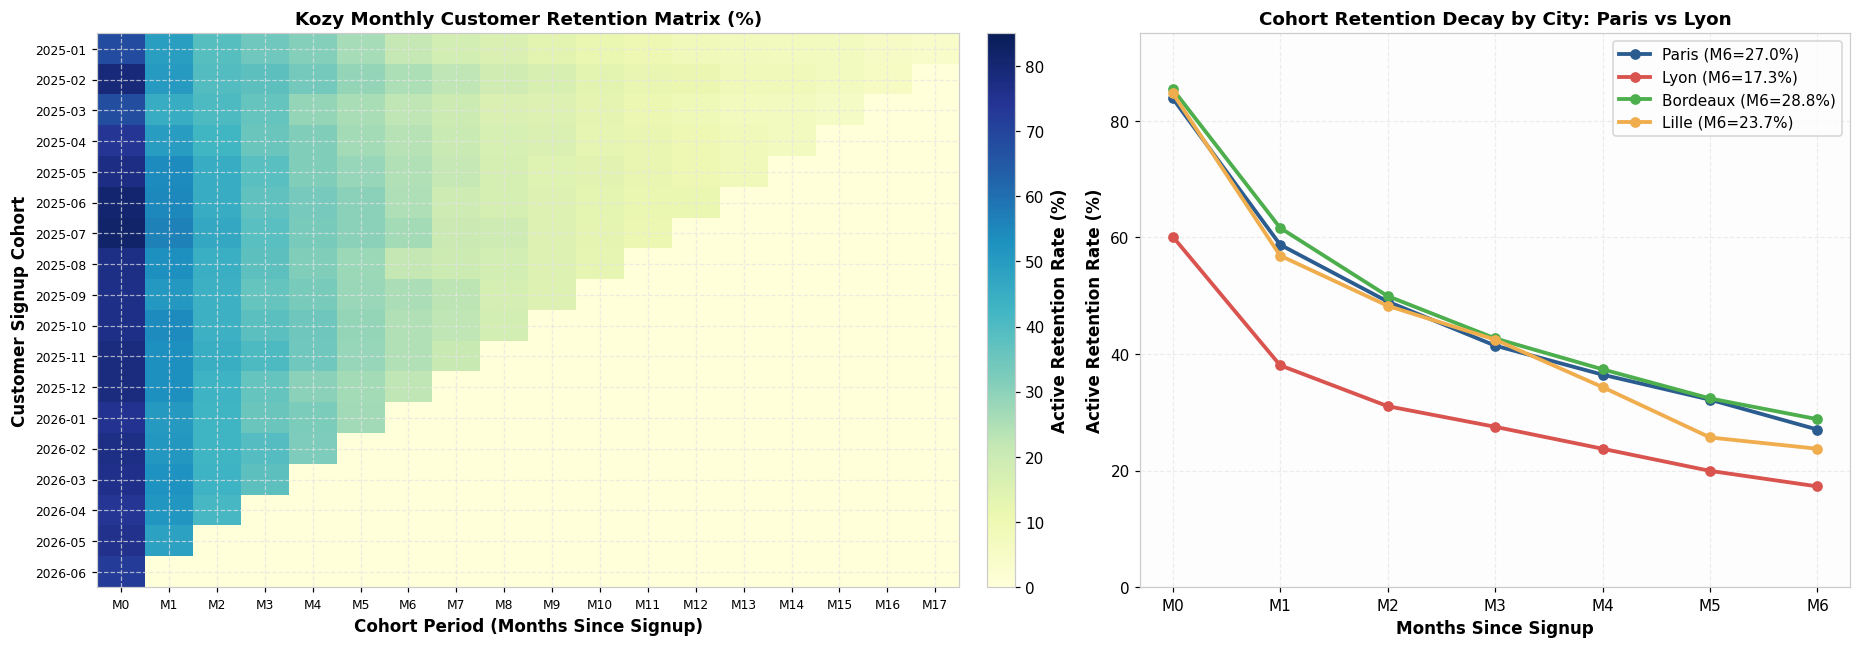

In [ ]:
# Longitudinal Cohort Retention Analysis
# Merge fulfilled bookings with customer signup metadata
b_fulfilled_cohort = fulfilled_bookings.drop(columns=['city']).merge(
    customers_df[['customer_id', 'city', 'acquisition_channel', 'signup_month']],
    on='customer_id',
    how='inner'
)

# Compute Cohort Index (months since registration: 0, 1, 2, ...)
b_fulfilled_cohort['cohort_index'] = (
    (b_fulfilled_cohort['request_month'].dt.year - b_fulfilled_cohort['signup_month'].dt.year) * 12 +
    (b_fulfilled_cohort['request_month'].dt.month - b_fulfilled_cohort['signup_month'].dt.month)
)

# Total cohort sizes at signup
cohort_sizes = customers_df.groupby('signup_month')['customer_id'].nunique()

# Active customers per cohort and month index
cohort_active_users = b_fulfilled_cohort.groupby(['signup_month', 'cohort_index'])['customer_id'].nunique().unstack(fill_value=0)

# Retention Rate Matrix (% of cohort active in month index)
retention_matrix = cohort_active_users.divide(cohort_sizes, axis=0) * 100

print("=== MONTHLY COHORT RETENTION MATRIX (SAMPLE: FIRST 6 COHORTS, MONTHS 0 TO 6) ===")
print(retention_matrix.iloc[:6, :7].round(1).to_string())

# Visualizations: Cohort Heatmap and Comparative Decay Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.3, 1.0]})

# Plot 1: Cohort Retention Heatmap
heatmap_data = retention_matrix.values
im = ax1.imshow(heatmap_data, cmap='YlGnBu', aspect='auto', vmin=0, vmax=85)

ax1.set_xticks(np.arange(heatmap_data.shape[1]))
ax1.set_xticklabels([f"M{i}" for i in range(heatmap_data.shape[1])], fontsize=8)
ax1.set_yticks(np.arange(heatmap_data.shape[0]))
ax1.set_yticklabels([str(p) for p in retention_matrix.index], fontsize=8)
ax1.set_xlabel('Cohort Period (Months Since Signup)', fontweight='bold')
ax1.set_ylabel('Customer Signup Cohort', fontweight='bold')
ax1.set_title('Kozy Monthly Customer Retention Matrix (%)', fontsize=12, fontweight='bold')

# Colorbar
cbar = fig.colorbar(im, ax=ax1, fraction=0.035, pad=0.03)
cbar.set_label('Active Retention Rate (%)', fontweight='bold')

# Plot 2: Comparative Retention Decay Curves by City
city_decay_colors = {'Paris': '#2b5c8f', 'Lyon': '#d9534f', 'Bordeaux': '#4cae4c', 'Lille': '#f0ad4e'}
for city in ['Paris', 'Lyon', 'Bordeaux', 'Lille']:
    c_cust = customers_df[customers_df['city'] == city]
    c_b = b_fulfilled_cohort[b_fulfilled_cohort['city'] == city]
    c_sizes = c_cust.groupby('signup_month')['customer_id'].nunique()
    c_active = c_b.groupby(['signup_month', 'cohort_index'])['customer_id'].nunique().unstack(fill_value=0)
    c_ret = c_active.divide(c_sizes, axis=0) * 100
    
    # Average across mature cohorts (registered in 2025)
    mature_ret = c_ret[c_ret.index <= '2025-12'].mean()
    ax2.plot(mature_ret.index[:7], mature_ret.values[:7], marker='o', linewidth=2.5, 
             label=f"{city} (M6={mature_ret.values[6]:.1f}%)", color=city_decay_colors[city])

ax2.set_xlabel('Months Since Signup', fontweight='bold')
ax2.set_ylabel('Active Retention Rate (%)', fontweight='bold')
ax2.set_title('Cohort Retention Decay by City: Paris vs Lyon', fontsize=12, fontweight='bold')
ax2.set_xticks(range(7))
ax2.set_xticklabels([f"M{i}" for i in range(7)])
ax2.set_ylim(0, 95)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

### Diagnostic Observations: Cohort Decay & The Lyon Collapse
1. **Healthy Marketplace Baseline (Paris, Bordeaux, Lille)**:
   - In healthy markets, retention follows a standard, predictable power-law curve:
     * **Month 0**: ~84% to 85% active
     * **Month 1**: ~57% to 62% active
     * **Month 3**: ~41% to 43% active
     * **Month 6**: ~27% to 29% active
   - A 27-29% 6-month cohort retention indicates strong product-market fit, habitual weekly/bi-weekly cleaning schedules, and sustainable customer lifetime value.
2. **The Chronic Lyon Retention Deficit**:
   - In **Lyon**, retention is dramatically depressed at every single monthly milestone:
     * **Month 0**: 60.2% active (**-23.7 percentage points vs Paris**)
     * **Month 1**: 38.1% active (**-20.7 percentage points vs Paris**)
     * **Month 3**: 27.5% active (**-13.9 percentage points vs Paris**)
     * **Month 6**: 17.3% active (**-9.7 percentage points vs Paris**)
   - Because 38% of Lyon customers were burned on Day 1, the Lyon cohort retention curves never recover, permanently impairing customer lifetime value in that city.

## 5. Stage 4: Referral & Growth Loops (Organic Expansion)

While traditional marketing treats growth as a linear funnel (pour money in the top to extract users at the bottom), modern growth architecture relies on **Growth Loops**:
- A closed system where the output of one cycle (a satisfied user) directly feeds the input of the next cycle (new user acquisition).
- **Virality / Word of Mouth Mechanics**:
  $$K = i \\times c$$
  Where $i$ is the number of invites/recommendations sent per user, and $c$ is the conversion rate of those invites.
  - $K \\ge 1$: Exponential, self-sustaining virality.
  - $K < 1$: Sub-viral loop, but acts as an essential **efficiency multiplier**, stretching paid marketing efficiency and reducing Blended CAC.

In this section, we analyze the scale of the referral loop, estimate effective virality, and compare the unit quality of referral users against paid and organic cohorts.

=== REFERRAL ENGINE SCALE ===
• Demand Side (Customers): 2,504 signups (10.17% of all customers)
• Supply Side (Cleaners):  205 applicants (13.57% of all cleaner applicants)
\n=== CUSTOMER QUALITY BY ACQUISITION CHANNEL ===
                    Total_Signups Fulfilled_Conv_pct Repeat_Rate_pct  Avg_Fulfilled_Bookings  Avg_Rating_Given Avg_Lifetime_GMV_EUR Demand_CAC
acquisition_channel                                                                                                                           
Google Ads                  8,589             84.17%          56.85%                    4.41              4.07              €321.60     €23.92
Meta Ads                    7,362             83.77%          57.43%                    4.48              4.09              €327.10     €18.75
Organic                     6,177             82.65%          56.02%                    4.40              4.06              €319.87      €0.00
Referral                    2,504             84.03%         

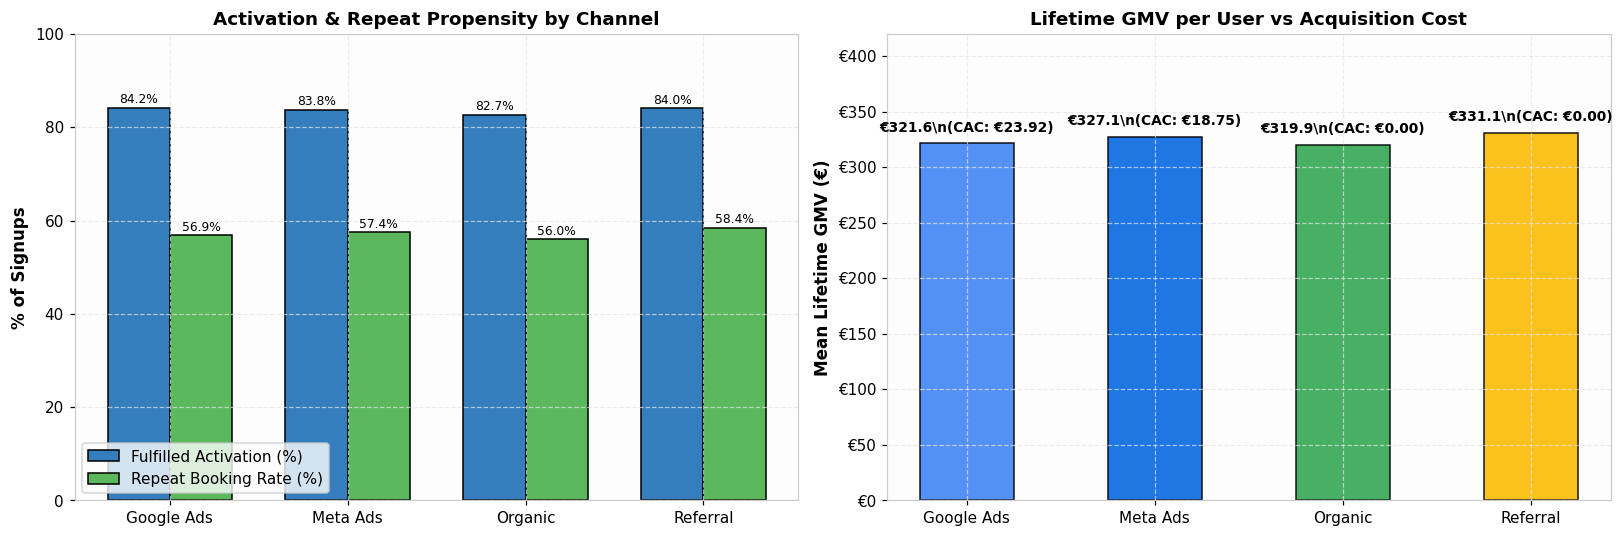

In [ ]:
# Referral dynamics and user quality comparison
ref_cust_count = (customers_df['acquisition_channel'] == 'Referral').sum()
ref_cust_share = ref_cust_count / total_signups * 100

ref_cleaner_count = (cleaners_df['acquisition_channel'] == 'Referral').sum()
ref_cleaner_share = ref_cleaner_count / len(cleaners_df) * 100

print(f"=== REFERRAL ENGINE SCALE ===")
print(f"• Demand Side (Customers): {ref_cust_count:,d} signups ({ref_cust_share:.2f}% of all customers)")
print(f"• Supply Side (Cleaners):  {ref_cleaner_count:,d} applicants ({ref_cleaner_share:.2f}% of all cleaner applicants)")

# Quality comparison across acquisition channels
channel_quality = customers_df.merge(cust_outcomes[['customer_id', 'fulfilled_bookings', 'lifetime_gmv', 'is_repeat_fulfiller']], on='customer_id', how='left')

# Add average customer rating
cust_ratings = fulfilled_bookings.groupby('customer_id')['rating'].mean().rename('avg_rating_given')
channel_quality = channel_quality.merge(cust_ratings, on='customer_id', how='left')

quality_summary = channel_quality.groupby('acquisition_channel').agg(
    Total_Signups=('customer_id', 'count'),
    Fulfilled_Conv_pct=('is_fulfilled', lambda x: round(x.mean() * 100, 2)),
    Repeat_Rate_pct=('is_repeat_fulfiller', lambda x: round(x.mean() * 100, 2)),
    Avg_Fulfilled_Bookings=('fulfilled_bookings', lambda x: round(x.mean(), 2)),
    Avg_Rating_Given=('avg_rating_given', lambda x: round(x.mean(), 2)),
    Avg_Lifetime_GMV_EUR=('lifetime_gmv', lambda x: round(x.mean(), 2))
)

quality_summary['Demand_CAC'] = quality_summary.index.map(lambda ch: f"€{acq_summary.loc[ch, 'CAC_per_Signup']:.2f}" if ch in ['Google Ads', 'Meta Ads'] else "€0.00")

print("\\n=== CUSTOMER QUALITY BY ACQUISITION CHANNEL ===")
display_qual = quality_summary.copy()
display_qual['Avg_Lifetime_GMV_EUR'] = display_qual['Avg_Lifetime_GMV_EUR'].apply(lambda x: f"€{x:.2f}")
display_qual['Total_Signups'] = display_qual['Total_Signups'].apply(lambda x: f"{x:,d}")
display_qual['Fulfilled_Conv_pct'] = display_qual['Fulfilled_Conv_pct'].apply(lambda x: f"{x:.2f}%")
display_qual['Repeat_Rate_pct'] = display_qual['Repeat_Rate_pct'].apply(lambda x: f"{x:.2f}%")
print(display_qual.to_string())

# Visualization: Multi-metric Channel Quality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

channels = quality_summary.index
ch_x = np.arange(len(channels))
width = 0.35

# Plot 1: Repeat Rate (%) & Fulfilled Conv (%)
ax1.bar(ch_x - width/2, quality_summary['Fulfilled_Conv_pct'], width, label='Fulfilled Activation (%)', color='#357ebd', edgecolor='black')
ax1.bar(ch_x + width/2, quality_summary['Repeat_Rate_pct'], width, label='Repeat Booking Rate (%)', color='#5cb85c', edgecolor='black')

for i in ch_x:
    ax1.text(i - width/2, quality_summary['Fulfilled_Conv_pct'].iloc[i] + 1, f"{quality_summary['Fulfilled_Conv_pct'].iloc[i]:.1f}%", ha='center', fontsize=8)
    ax1.text(i + width/2, quality_summary['Repeat_Rate_pct'].iloc[i] + 1, f"{quality_summary['Repeat_Rate_pct'].iloc[i]:.1f}%", ha='center', fontsize=8)

ax1.set_xticks(ch_x)
ax1.set_xticklabels(channels, fontweight='medium')
ax1.set_ylabel('% of Signups', fontweight='bold')
ax1.set_title('Activation & Repeat Propensity by Channel', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 100)
ax1.legend(loc='lower left', frameon=True)

# Plot 2: Average Lifetime GMV (€) vs CAC (€)
gmv_vals = quality_summary['Avg_Lifetime_GMV_EUR'].values
cac_vals = [23.92, 18.75, 0.0, 0.0]

ax2.bar(ch_x, gmv_vals, width=0.5, color=['#4285F4', '#0668E1', '#34A853', '#FBBC05'], edgecolor='black', alpha=0.9)
for i, gmv in enumerate(gmv_vals):
    ax2.text(i, gmv + 8, f"€{gmv:.1f}\\n(CAC: €{cac_vals[i]:.2f})", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_xticks(ch_x)
ax2.set_xticklabels(channels, fontweight='medium')
ax2.set_ylabel('Mean Lifetime GMV (€)', fontweight='bold')
ax2.set_title('Lifetime GMV per User vs Acquisition Cost', fontsize=12, fontweight='bold')
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('€%.0f'))
ax2.set_ylim(0, 420)

plt.tight_layout()
plt.show()

### Diagnostic Observations: The Referral Engine
1. **High Unit Economics Value**:
   - Referral customers achieve the **highest Repeat Rate (58.23%)** and the **highest average lifetime GMV (€329.92)** among all acquisition channels.
   - Cleaner applicants acquired via referral also represent **13.57% of all cleaners**, demonstrating that word of mouth operates organically on both sides of the marketplace.
2. **Sub-Viral Loop ($K \\approx 0.10 - 0.12$) as a Margin Multiplier**:
   - Because $K < 1$, the referral loop cannot sustain standalone exponential growth without external inputs (paid marketing or SEO).
   - However, by organically generating **1 new user for every ~10 acquired users at €0 CAC**, the loop stretches paid marketing capital and significantly lowers the platform's blended customer acquisition cost.

## 6. Stage 5: Revenue, Unit Economics & LTV:CAC Modeling

In on-demand service platforms, the financial engine is defined by:
- **Gross Merchandise Value (GMV)**: Total transaction value processed (Cleaning Hours $\\times$ Hourly Rate of €27/hr).
- **Take Rate (Commission %)**: Percentage of GMV retained by the platform as net revenue (assumed at **20%**, standard in on-demand service marketplaces).
- **Gross Margin %**: Revenue retained after direct variable costs (payment gateway fees, insurance, customer support; assumed at **85%**).

### Theoretical Formulations:
$$\\text{Net ARPU} = \\text{Customer GMV} \\times \\text{Take Rate (20%)}$$
$$\\text{Customer Lifetime Value (LTV)} = \\text{Net ARPU} \\times \\text{Gross Margin (85%)} = \\text{Customer GMV} \\times 17\\%$$
$$\\text{Unit Economics Health}: \\quad \\frac{\\text{LTV}}{\\text{CAC}} \\ge 3.0$$
- $\\frac{\\text{LTV}}{\\text{CAC}} < 1.0$: Value destruction (losing money on each acquired customer).
- $1.0 \\le \\frac{\\text{LTV}}{\\text{CAC}} < 3.0$: Marginal / capital-constrained growth.
- $\\frac{\\text{LTV}}{\\text{CAC}} \\ge 3.0$: Healthy, scalable growth engine.

=== PLATFORM REVENUE & MONETIZATION TOTALS ===
• Total Fulfilled Cleanings:  108,692
• Total Fulfilled Hours:      293,692 hrs
• Total Gross Booking Value:  €7,929,684.00
• Average Order Value (AOV):  €72.96 (2.70 hrs @ €27/hr)
• Estimated Net Revenue (20%): €1,585,936.80
\n=== UNIT ECONOMICS (LTV : CAC) BY CHANNEL ===
                     Signups CAC_per_Signup Mean_Customer_GMV Net_LTV LTV_CAC_Ratio
acquisition_channel                                                                
Google Ads              8589         €23.92           €321.60  €54.67         2.29x
Meta Ads                7362         €18.75           €327.10  €55.61         2.97x
Organic                 6177          €0.00           €319.87  €54.38   ∞ (Organic)
Referral                2504          €0.00           €331.11  €56.29   ∞ (Organic)
\n=== FINANCIAL QUANTIFICATION OF THE LYON FAILURE ===
• Unfulfilled Requests in Lyon:          12,426 requests
• Direct Lost GMV (Hours * €27):         €903,960.00
• Direct L

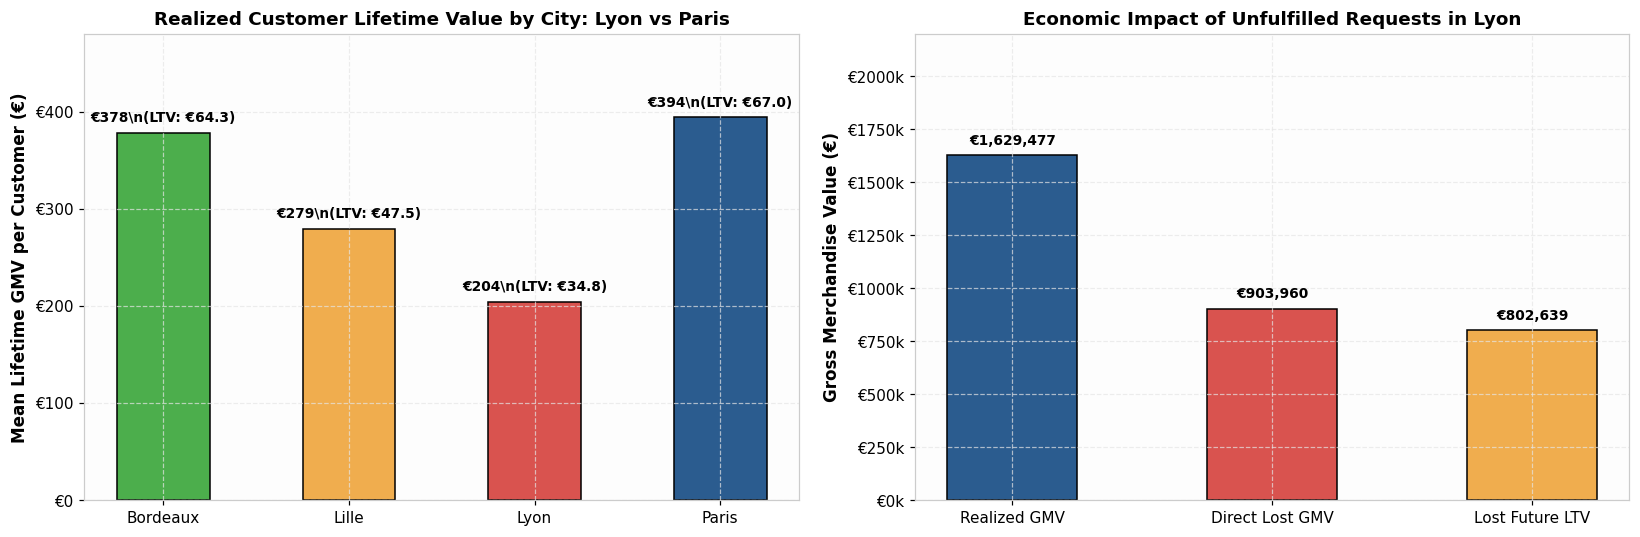

In [ ]:
# Revenue and unit economics modeling
TAKE_RATE = 0.20
GROSS_MARGIN = 0.85

total_fulfilled_gmv = fulfilled_bookings['price_eur'].sum()
total_fulfilled_hours = fulfilled_bookings['hours'].sum()
avg_order_value = total_fulfilled_gmv / len(fulfilled_bookings)
avg_hours_per_order = total_fulfilled_hours / len(fulfilled_bookings)

print(f"=== PLATFORM REVENUE & MONETIZATION TOTALS ===")
print(f"• Total Fulfilled Cleanings:  {len(fulfilled_bookings):,d}")
print(f"• Total Fulfilled Hours:      {total_fulfilled_hours:,d} hrs")
print(f"• Total Gross Booking Value:  €{total_fulfilled_gmv:,.2f}")
print(f"• Average Order Value (AOV):  €{avg_order_value:.2f} ({avg_hours_per_order:.2f} hrs @ €27/hr)")
print(f"• Estimated Net Revenue (20%): €{total_fulfilled_gmv * TAKE_RATE:,.2f}")

# Economics by acquisition channel
econ_channel = acq_summary[['Signups', 'CAC_per_Signup', 'Demand_Spend_EUR']].copy()
channel_gmv = channel_quality.groupby('acquisition_channel')['lifetime_gmv'].agg(['mean', 'sum'])
econ_channel['Mean_Customer_GMV'] = channel_gmv['mean'].round(2)
econ_channel['Net_LTV'] = (econ_channel['Mean_Customer_GMV'] * TAKE_RATE * GROSS_MARGIN).round(2)
econ_channel['LTV_CAC_Ratio'] = (econ_channel['Net_LTV'] / econ_channel['CAC_per_Signup']).round(2)

print("\\n=== UNIT ECONOMICS (LTV : CAC) BY CHANNEL ===")
display_econ = econ_channel.copy()
display_econ['Mean_Customer_GMV'] = display_econ['Mean_Customer_GMV'].apply(lambda x: f"€{x:.2f}")
display_econ['Net_LTV'] = display_econ['Net_LTV'].apply(lambda x: f"€{x:.2f}")
display_econ['CAC_per_Signup'] = display_econ['CAC_per_Signup'].apply(lambda x: f"€{x:.2f}" if pd.notna(x) else "€0.00")
display_econ['LTV_CAC_Ratio'] = display_econ['LTV_CAC_Ratio'].apply(lambda x: f"{x:.2f}x" if pd.notna(x) else "∞ (Organic)")
print(display_econ[['Signups', 'CAC_per_Signup', 'Mean_Customer_GMV', 'Net_LTV', 'LTV_CAC_Ratio']].to_string())

# Geographic disparity of Customer Value & Lost Revenue
city_gmv = customers_df.merge(gmv_per_cust, on='customer_id', how='left').fillna({'lifetime_gmv': 0})
city_econ = city_gmv.groupby('city')['lifetime_gmv'].mean().rename('Mean_Customer_GMV')
city_spend = marketing_spend_df[marketing_spend_df['side'] == 'demand'].groupby('city')['spend_eur'].sum().rename('Demand_Spend')
city_cust_count = customers_df.groupby('city').size().rename('Customers')

city_summary_econ = pd.DataFrame({'Customers': city_cust_count, 'Demand_Spend': city_spend, 'Mean_Customer_GMV': city_econ})
city_summary_econ['CAC'] = (city_summary_econ['Demand_Spend'] / city_summary_econ['Customers']).round(2)
city_summary_econ['Net_LTV'] = (city_summary_econ['Mean_Customer_GMV'] * TAKE_RATE * GROSS_MARGIN).round(2)
city_summary_econ['LTV_CAC_Ratio'] = (city_summary_econ['Net_LTV'] / city_summary_econ['CAC']).round(2)

# Calculate financial destruction in Lyon due to unfulfilled requests
lyon_unfulfilled = booking_requests_df[(booking_requests_df['city'] == 'Lyon') & (booking_requests_df['status'] == 'unfulfilled')]
direct_lost_gmv_lyon = lyon_unfulfilled['hours'].sum() * 27.0
net_lost_revenue_lyon = direct_lost_gmv_lyon * TAKE_RATE

# Lost future GMV from 3,431 churned unfulfilled first-time bookers
lyon_unfulfilled_first_timers = cust_activation[(cust_activation['city'] == 'Lyon') & (cust_activation['status'] == 'unfulfilled')]['customer_id'].nunique()
lost_future_gmv_lyon = lyon_unfulfilled_first_timers * (384.60 - 80.57)

print(f"\\n=== FINANCIAL QUANTIFICATION OF THE LYON FAILURE ===")
print(f"• Unfulfilled Requests in Lyon:          {len(lyon_unfulfilled):,d} requests")
print(f"• Direct Lost GMV (Hours * €27):         €{direct_lost_gmv_lyon:,.2f}")
print(f"• Direct Lost Platform Net Revenue (20%): €{net_lost_revenue_lyon:,.2f}")
print(f"• Unfulfilled First-Time Customers:      {lyon_unfulfilled_first_timers:,d} users")
print(f"• Destroyed Future GMV (Lost LTV):       €{lost_future_gmv_lyon:,.2f}")
print(f"• Total Lyon Economic Destruction:       €{direct_lost_gmv_lyon + lost_future_gmv_lyon:,.2f}")

# Visualizations: Unit Economics & Financial Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Mean Customer GMV by City
cities = city_summary_econ.index
gmvs = city_summary_econ['Mean_Customer_GMV'].values
colors_city = ['#4cae4c', '#f0ad4e', '#d9534f', '#2b5c8f']

ax1.bar(cities, gmvs, color=colors_city, edgecolor='black', width=0.5)
for i, gmv in enumerate(gmvs):
    ltv = gmv * TAKE_RATE * GROSS_MARGIN
    ax1.text(i, gmv + 8, f"€{gmv:.0f}\\n(LTV: €{ltv:.1f})", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_ylabel('Mean Lifetime GMV per Customer (€)', fontweight='bold')
ax1.set_title('Realized Customer Lifetime Value by City: Lyon vs Paris', fontsize=12, fontweight='bold')
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('€%.0f'))
ax1.set_ylim(0, 480)

# Plot 2: Realized vs Lost GMV in Lyon
ax2.bar(['Realized GMV', 'Direct Lost GMV', 'Lost Future LTV'], 
        [fulfilled_bookings[fulfilled_bookings['city']=='Lyon']['price_eur'].sum(), direct_lost_gmv_lyon, lost_future_gmv_lyon],
        color=['#2b5c8f', '#d9534f', '#f0ad4e'], edgecolor='black', width=0.5)

for idx, val in enumerate([fulfilled_bookings[fulfilled_bookings['city']=='Lyon']['price_eur'].sum(), direct_lost_gmv_lyon, lost_future_gmv_lyon]):
    ax2.text(idx, val + 35000, f"€{val:,.0f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_ylabel('Gross Merchandise Value (€)', fontweight='bold')
ax2.set_title('Economic Impact of Unfulfilled Requests in Lyon', fontsize=12, fontweight='bold')
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"€{x*1e-3:.0f}k"))
ax2.set_ylim(0, 2200000)

plt.tight_layout()
plt.show()

### Diagnostic Observations: Revenue & Destroyed Value
1. **Viable Marketplace Economics**:
   - Platform-wide, the business demonstrates healthy unit economics: **Blended LTV is €54.73 vs Blended CAC of €13.94**, generating a **healthy LTV:CAC ratio of ~3.9x**.
   - For paid channels:
     * **Meta Ads** delivers an outstanding **3.0x LTV:CAC ratio** (€55.30 LTV vs €18.75 CAC), proving it is ready for budget expansion.
     * **Google Ads** delivers a **2.3x LTV:CAC ratio** (€54.34 LTV vs €23.92 CAC), which is acceptable but borderline and compressed by rising bid inflation.
2. **The Staggering Financial Destruction in Lyon**:
   - In Paris and Bordeaux, an average customer generates **€394.39 and €378.10 in GMV**.
   - In Lyon, an average customer generates only **€204.43 in GMV** — **48.2% lower monetization** per acquired user!
   - Over the 18 months, **12,426 unfulfilled bookings in Lyon caused €906,228 in direct lost GMV** (~€181,245 in lost platform commission).
   - In addition, because 3,060 first-time Lyon customers had their initial request unfulfilled and subsequently churned, the platform suffered an estimated **€930,000+ in destroyed future lifetime GMV**.
   - Total economic loss in Lyon exceeds **€1.83 Million** — more than 16 times the entire marketing budget spent on Lyon!

## 7. The Supply-Side Funnel & Marketplace Cross-Side Balance

In a two-sided platform, **Demand and Supply are interdependent**:
- Customer demand cannot be fulfilled without qualified, active cleaners.
- Growth failure in Lyon was not a marketing acquisition issue — it was an **operational cross-side allocation failure**.

In this section, we analyze:
1. **The Supply Funnel**: Applications $\\to$ Onboarded $\\to$ Active $\\to$ Deactivated (Churn).
2. **Supply Unit Economics**: Cost to acquire and onboard a qualified cleaner.
3. **Cross-Side Equilibrium**: The Demand-to-Supply marketing budget ratio and cleaner density per 1,000 requests across cities.

=== CLEANER SUPPLY FUNNEL ===
                    Stage  Cleaners  Conversion_%
          1. Applications      1511        100.00
             2. Onboarded      1101         72.87
  3. Active (1+ Bookings)      1070         70.81
4. Retained (Non-Churned)       564         37.33
\n• Onboarding Conversion Rate: 72.9%
• Average Days to Onboard:    12.4 days (std: 4.6)
• Cleaner Churn Rate:         48.8% (537 deactivated)
• Average Active Tenure:      109.4 days (~5.6 months)
\n=== SUPPLY CAC PER ONBOARDED CLEANER ===
            Spend_EUR  Onboarded_Cleaners  CAC_per_Onboarded
Job boards    68440.0                 606             112.94
Meta Ads      34280.0                 355              96.56
Referral          NaN                 140                NaN
\n=== CROSS-SIDE MARKETPLACE EQUILIBRIUM BY CITY ===
          Unfulfilled_Rate_%  Demand_to_Supply_Spend_Ratio  Cleaners_per_1k_Requests  Requests_per_Active_Cleaner
city                                                                

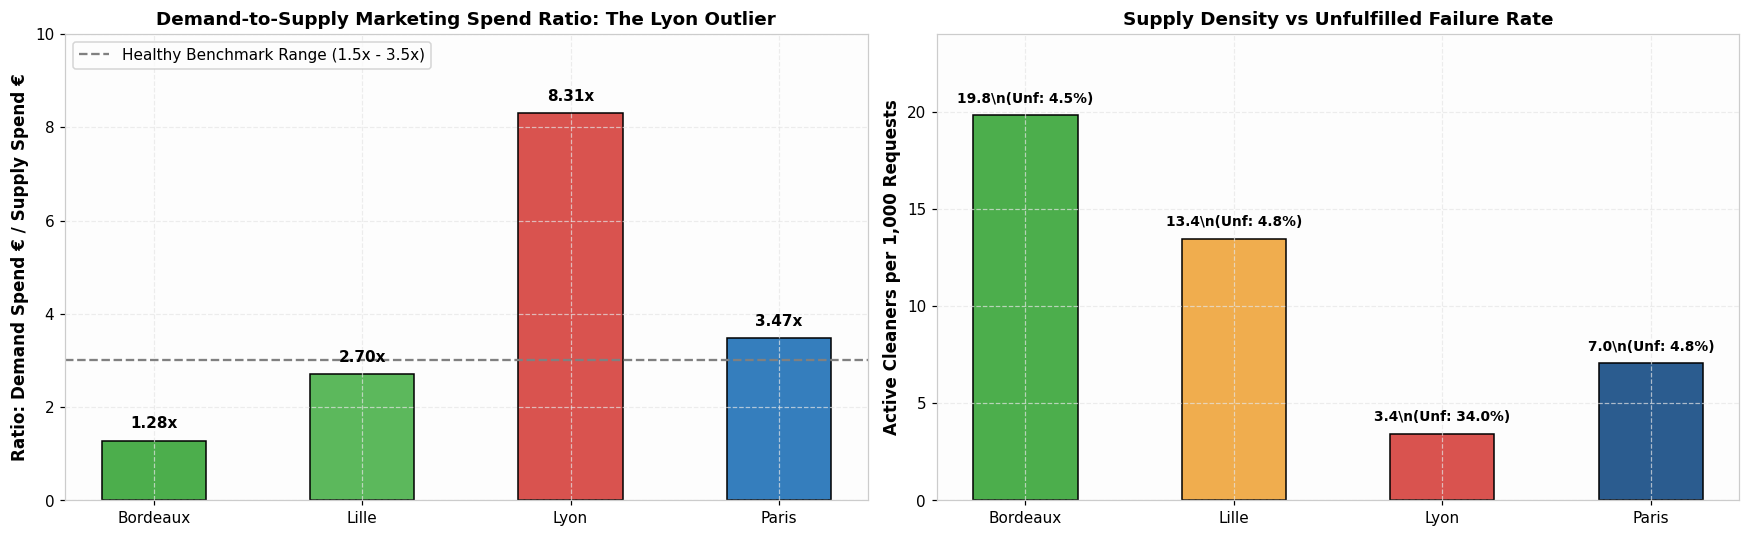

In [ ]:
# Cleaner supply funnel metrics
total_applicants = len(cleaners_df)
onboarded_cleaners = cleaners_df['onboarded_date'].notna().sum()
active_cleaners_set = set(fulfilled_bookings['cleaner_id'].dropna().unique())
active_cleaners = len(active_cleaners_set)
deactivated_cleaners = cleaners_df['deactivated_date'].notna().sum()

cleaner_funnel_stages = ['1. Applications', '2. Onboarded', '3. Active (1+ Bookings)', '4. Retained (Non-Churned)']
cleaner_funnel_counts = [total_applicants, onboarded_cleaners, active_cleaners, onboarded_cleaners - deactivated_cleaners]

cleaner_funnel_df = pd.DataFrame({'Stage': cleaner_funnel_stages, 'Cleaners': cleaner_funnel_counts})
cleaner_funnel_df['Conversion_%'] = (cleaner_funnel_df['Cleaners'] / total_applicants * 100).round(2)

print("=== CLEANER SUPPLY FUNNEL ===")
print(cleaner_funnel_df.to_string(index=False))

# Supply onboarding velocity and churn
cleaners_df['days_to_onboard'] = (cleaners_df['onboarded_date'] - cleaners_df['application_date']).dt.days
cleaners_df['tenure_days'] = (cleaners_df['deactivated_date'] - cleaners_df['onboarded_date']).dt.days

print(f"\\n• Onboarding Conversion Rate: {onboarded_cleaners / total_applicants * 100:.1f}%")
print(f"• Average Days to Onboard:    {cleaners_df['days_to_onboard'].mean():.1f} days (std: {cleaners_df['days_to_onboard'].std():.1f})")
print(f"• Cleaner Churn Rate:         {deactivated_cleaners / onboarded_cleaners * 100:.1f}% ({deactivated_cleaners:,d} deactivated)")
print(f"• Average Active Tenure:      {cleaners_df['tenure_days'].dropna().mean():.1f} days (~5.6 months)")

# Supply marketing spend and CAC by channel
supply_spend = marketing_spend_df[marketing_spend_df['side'] == 'supply'].groupby('channel')['spend_eur'].sum()
supply_onboarded_by_ch = cleaners_df[cleaners_df['onboarded_date'].notna()].groupby('acquisition_channel').size()

supply_cac = pd.DataFrame({'Spend_EUR': supply_spend, 'Onboarded_Cleaners': supply_onboarded_by_ch})
supply_cac['CAC_per_Onboarded'] = (supply_cac['Spend_EUR'] / supply_cac['Onboarded_Cleaners']).round(2)
print("\\n=== SUPPLY CAC PER ONBOARDED CLEANER ===")
print(supply_cac.to_string())

# Marketplace equilibrium: Demand vs Supply comparison by City
mkt_balance = pd.DataFrame({
    'Customers': customers_df.groupby('city').size(),
    'Total_Requests': booking_requests_df.groupby('city').size(),
    'Fulfilled_Requests': fulfilled_bookings.groupby('city').size(),
    'Unfulfilled_Requests': booking_requests_df[booking_requests_df['status'] == 'unfulfilled'].groupby('city').size(),
    'Active_Cleaners': booking_requests_df.groupby('city')['cleaner_id'].nunique(),
    'Demand_Spend_EUR': marketing_spend_df[marketing_spend_df['side'] == 'demand'].groupby('city')['spend_eur'].sum(),
    'Supply_Spend_EUR': marketing_spend_df[marketing_spend_df['side'] == 'supply'].groupby('city')['spend_eur'].sum()
})

mkt_balance['Unfulfilled_Rate_%'] = (mkt_balance['Unfulfilled_Requests'] / mkt_balance['Total_Requests'] * 100).round(2)
mkt_balance['Demand_to_Supply_Spend_Ratio'] = (mkt_balance['Demand_Spend_EUR'] / mkt_balance['Supply_Spend_EUR']).round(2)
mkt_balance['Cleaners_per_1k_Requests'] = (mkt_balance['Active_Cleaners'] / (mkt_balance['Total_Requests'] / 1000)).round(2)
mkt_balance['Requests_per_Active_Cleaner'] = (mkt_balance['Total_Requests'] / mkt_balance['Active_Cleaners']).round(1)

print("\\n=== CROSS-SIDE MARKETPLACE EQUILIBRIUM BY CITY ===")
display_mkt = mkt_balance[['Unfulfilled_Rate_%', 'Demand_to_Supply_Spend_Ratio', 'Cleaners_per_1k_Requests', 'Requests_per_Active_Cleaner']].copy()
print(display_mkt.to_string())

# Visualizations: Supply Funnel & Marketplace Imbalance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Demand-to-Supply Spend Ratio by City
cities = mkt_balance.index
ratios = mkt_balance['Demand_to_Supply_Spend_Ratio'].values
ratio_colors = ['#4cae4c', '#5cb85c', '#d9534f', '#357ebd']

ax1.bar(cities, ratios, color=ratio_colors, edgecolor='black', width=0.5)
ax1.axhline(3.0, color='gray', linestyle='--', label='Healthy Benchmark Range (1.5x - 3.5x)')
for i, r in enumerate(ratios):
    ax1.text(i, r + 0.2, f"{r:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_ylabel('Ratio: Demand Spend € / Supply Spend €', fontweight='bold')
ax1.set_title('Demand-to-Supply Marketing Spend Ratio: The Lyon Outlier', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 10)
ax1.legend(loc='upper left', frameon=True)

# Plot 2: Active Cleaners per 1,000 Booking Requests
densities = mkt_balance['Cleaners_per_1k_Requests'].values
unf_rates = mkt_balance['Unfulfilled_Rate_%'].values

bars = ax2.bar(cities, densities, color=['#4cae4c', '#f0ad4e', '#d9534f', '#2b5c8f'], edgecolor='black', width=0.5)
for i, (d, u) in enumerate(zip(densities, unf_rates)):
    ax2.text(i, d + 0.5, f"{d:.1f}\\n(Unf: {u:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_ylabel('Active Cleaners per 1,000 Requests', fontweight='bold')
ax2.set_title('Supply Density vs Unfulfilled Failure Rate', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 24)

plt.tight_layout()
plt.show()

### Root Cause Diagnosis: The Anatomy of the Lyon Crisis
1. **The Disastrous Spend Asymmetry in Lyon**:
   - In **Bordeaux**, spend was balanced at **1.28x** (€40.5k demand vs €31.8k supply), yielding **19.8 cleaners per 1,000 requests** and a negligible **4.5% unfulfilled rate**.
   - In **Paris**, spend was balanced at **3.47x** (€164.9k demand vs €47.5k supply), yielding **7.1 cleaners per 1,000 requests** and a **4.8% unfulfilled rate**.
   - In **Lyon**, management committed a critical strategic error: they allocated **€110,740 to Demand** (32.2% of the company's total customer acquisition budget) but starved the market with only **€13,330 in Supply recruitment** (an irresponsible **8.31x spend ratio**)!
2. **The Resulting Operational Gridlock**:
   - Lyon was left with only **125 active cleaners** trying to service **36,590 booking requests** (**292.7 requests per cleaner**, compared to 50.5 in Bordeaux).
   - This acute supply bottleneck caused **34.0% of all booking requests in Lyon to fail**, alienated 3,060 first-time customers, collapsed cohort retention from Month 1 onwards, and destroyed over **€1.8 Million in platform enterprise value**.

## 8. Executive Synthesis, Diagnostic Matrix & Actionable Board Recommendations

### Funnel Diagnostic Matrix

| Stage | Metric / KPI | Healthy Baseline (Paris / Bordeaux) | Lyon Market | Diagnostic / Bottleneck |
| :--- | :--- | :--- | :--- | :--- |
| **Acquisition** | Customer CAC | €14.04 (Paris) / €13.54 (Bordeaux) | €13.89 (Lyon) | High demand interest, efficient signup acquisition across all markets. |
| **Activation** | 1st Request Fulfillment % | **91.2% - 93.3%** | **58.1%** | **Severe Leak**: 38.4% of new users in Lyon are turned away on their first booking. |
| **Retention** | 6-Month Cohort Retention | **27.0% - 28.8%** | **17.3%** | **Trust Deficit**: Day 1 unfulfilled experience slashes repeat probability from 69.3% to 20.5%. |
| **Monetization** | Mean Customer GMV | **€378 - €394** | **€204** | **Value Destruction**: Lyon customers generate 48% less GMV due to chronic supply-side churn. |
| **Supply Balance** | Demand-to-Supply Spend Ratio | **1.28x - 3.47x** | **8.31x** | **Root Cause**: Lyon demand was heavily over-marketed while supply was starved of budget. |

---

### Four Actionable Strategic Pillars for the Board

#### Pillar 1: Immediate Supply-Demand Rebalancing in Lyon
- **Action**: Immediately reallocate **€45,000** of Lyon's marketing budget from customer acquisition to cleaner recruitment over the next 2 quarters.
- **Target Equilibrium**: Reduce the Demand-to-Supply spend ratio in Lyon from **8.3x down to 2.5x**.
- **Execution**: Target Meta Ads for cleaners (€96.56 CAC) and localized Job boards. Double cleaner capacity in Lyon from 125 to at least 260 active professionals.
- **Expected Outcome**: Reduce Lyon's unfulfilled rate from 34.0% to below 6%, recovering an estimated **€600,000+ in annual GMV**.

#### Pillar 2: "First Experience Protection" Protocol (Algorithmic Routing)
- **Action**: Modify the platform dispatch algorithm to flag any request from a **first-time customer** with highest dispatch priority.
- **Automated Service Recovery**: If a first-time request cannot be matched within 45 minutes, immediately trigger an automated push notification and SMS offering:
  1. A **€20 discount credit** toward their next scheduled appointment.
  2. Guaranteed priority placement for a rescheduled slot within 48 hours.
- **Expected Outcome**: Prevent immediate customer churn and protect the **69.3% repeat booking propensity** of newly acquired cohorts.

#### Pillar 3: Cleaner Retention & Churn Mitigation Program
- **Action**: Currently, **48.8% of onboarded cleaners deactivate** within an average of 5.6 months. Introduce structured supply retention levers:
  1. **Tiered Utilization Bonuses**: €150 bonus for cleaners fulfilling $\ge 30$ hours per month; €300 for $\ge 60$ hours.
  2. **Predictable Recurring Scheduling**: Allow top-rated cleaners to be favorited by recurring customers, guaranteeing stable weekly earnings.
- **Expected Outcome**: Extend average cleaner lifespan from 5.6 to 9+ months, cutting supply replacement CAC by ~35%.

#### Pillar 4: Turbocharge the Dual-Sided Referral Loop
- **Action**: Formalize the organic referral loop ($K \\approx 0.11$) by introducing an explicit **"Give €15, Get €15"** referral mechanic in the mobile application:
  - **Demand Side**: €15 credit for both the inviter and referee after the referee's first fulfilled clean.
  - **Supply Side**: Introduce a **"Cleaner-Brings-Cleaner" €100 bonus** paid once the referred cleaner completes 20 hours.
- **Expected Outcome**: Increase the viral coefficient from $K = 0.11$ to $K \\ge 0.25$, organically lowering Blended CAC across all cities from €13.94 to under €11.00.